In [1]:

import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt  

df = pd.read_csv('indian_tech_jobs_2026.csv')

In [2]:
df_IND = df[df["location"] == "scraped_city"]

In [3]:
# Drop rows without skills and split each string into a clean list
df_IND = df.dropna(subset=['skills_required']).copy()

df_IND['skills_list'] = df_IND['skills_required'].apply(
    lambda x: [skill.strip() for skill in x.split(',') if skill.strip() not in ['', 'Not Available']]
)

In [4]:
df_skills = df_IND.explode('skills_list')

In [5]:
df_skills_count = df_skills.groupby(['skills_list', 'job_title']).size().reset_index(name='skill_count')


df_skills_count = df_skills_count.sort_values(by='skill_count', ascending=False)

df_skills_count.head()



,skills_list,job_title,skill_count
15914,Business Analyst,Business Analyst,328
29580,Data Engineering,Data Engineer,286
17061,Business analysis,Business Analyst,270
81848,SQL,Data Engineer,218
74818,Python,Data Engineer,216


In [7]:
job_titles = df_skills_count['job_title'].unique().tolist()

job_titles = sorted(job_titles[:3])

job_titles

['Business Analyst', 'Data Engineer', 'Data Scientist']

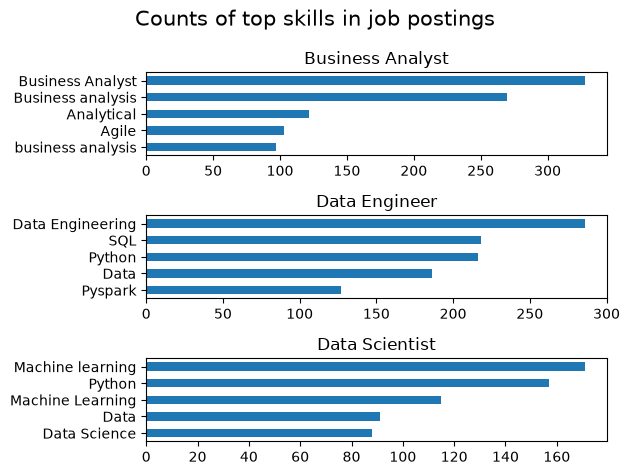

In [21]:
fig, ax = plt.subplots(len(job_titles), 1)

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_count[df_skills_count['job_title'] == job_title].head(5)
    df_plot.plot(kind='barh', x='skills_list', y='skill_count', ax=ax[i], title=job_title)
    ax[i].invert_yaxis()
    ax[i].set_ylabel('')
    ax[i].legend().set_visible(False)


fig.suptitle('Counts of top skills in job postings', fontsize=15)
plt.tight_layout()
plt.show()

In [28]:
df_job_title_count = df_IND['job_title'].value_counts().reset_index(name='jobs_total')

In [23]:
df_skills_count

,skills_list,job_title,skill_count
15914,Business Analyst,Business Analyst,328
29580,Data Engineering,Data Engineer,286
17061,Business analysis,Business Analyst,270
81848,SQL,Data Engineer,218
74818,Python,Data Engineer,216
...,...,...,...
127651,xcode,"Mobile Application Developer, Flutter Developer",1
127652,xero,Senior Business Analyst,1
127653,xml,AI Workflow Engineer & Agent Builder,1
127654,xml,Business Analyst,1


In [36]:

df_skills_perc = pd.merge(df_skills_count, df_job_title_count, how='left', on='job_title')

df_skills_perc['skill_percent'] = 100 * df_skills_perc['skill_count'] / df_skills_perc['jobs_total']

df_skills_perc


,skills_list,job_title,skill_count,jobs_total,skill_percent
0,Business Analyst,Business Analyst,328,829,39.565742
1,Data Engineering,Data Engineer,286,847,33.766234
2,Business analysis,Business Analyst,270,829,32.569361
3,SQL,Data Engineer,218,847,25.737898
4,Python,Data Engineer,216,847,25.501771
...,...,...,...,...,...
127667,xcode,"Mobile Application Developer, Flutter Developer",1,1,100.000000
127668,xero,Senior Business Analyst,1,131,0.763359
127669,xml,AI Workflow Engineer & Agent Builder,1,2,50.000000
127670,xml,Business Analyst,1,829,0.120627


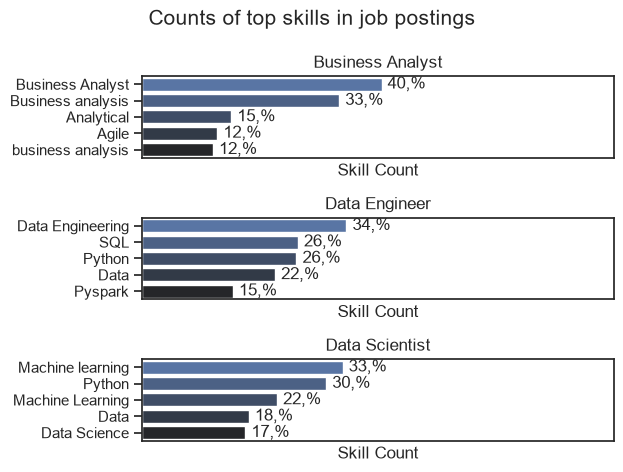

In [66]:
fig, ax = plt.subplots(len(job_titles), 1)

sns.set_theme(style='ticks')

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_perc[df_skills_perc['job_title'] == job_title].head(5) 
    sns.barplot(
        data=df_plot, 
        x='skill_percent',   # <-- use percentage column here
        y='skills_list', 
        ax=ax[i], 
        hue='skills_list', 
        palette='dark:b_r',
        legend=False
    )

    for n, v in enumerate(df_plot['skill_percent']):
        ax[i].text(v + 1, n, f'{v:.0f},%', va='center')


    ax[i].set_xticks([])
    ax[i].set_title(job_title)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('Skill Count')
    ax[i].set_xlim(0, 78)
fig.suptitle('Counts of top skills in job postings', fontsize=15)
plt.tight_layout()
plt.show()